In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

In [3]:
train = pd.read_csv("../../data/processed/train_features_138.csv")

X = train.drop(columns=["id", "target"])
y = train["target"]

print("X:", X.shape)
print("y:", y.shape)
print("Classes:", y.nunique())
print("Missing values:", X.isna().sum().sum())

X: (635, 138)
y: (635,)
Classes: 12
Missing values: 0


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (508, 138)
X_val: (127, 138)
y_train: (508,)
y_val: (127,)


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)

Train: (508, 138)
Validation: (127, 138)


In [9]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}

grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X_train, y_train)

print("Best k:", grid.best_params_)
print("Best CV Macro F1:", grid.best_score_)

Best k: {'knn__n_neighbors': 11}
Best CV Macro F1: 0.6470730184399588


In [11]:
best_knn = grid.best_estimator_

y_val_pred = best_knn.predict(X_val)

from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Macro F1:", f1_score(y_val, y_val_pred, average="macro"))
print("Validation Weighted F1:", f1_score(y_val, y_val_pred, average="weighted"))

print("\nClassification Report:\n")
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.7007874015748031
Validation Macro F1: 0.6826400162117171
Validation Weighted F1: 0.6983455641359388

Classification Report:

                 precision    recall  f1-score   support

  arm_elevation       0.77      0.91      0.83        11
climbing_stairs       0.38      0.27      0.32        11
        cycling       0.62      0.83      0.71        12
        jogging       0.86      1.00      0.92        12
jump_front_back       1.00      0.33      0.50         3
  knees_bending       0.36      0.50      0.42        10
          lying       1.00      1.00      1.00        12
        running       1.00      0.91      0.95        11
        sitting       1.00      0.73      0.84        11
       standing       0.45      0.42      0.43        12
    waist_bends       1.00      0.50      0.67        10
        walking       0.53      0.67      0.59        12

       accuracy                           0.70       127
      macro avg       0.75      0.67      0.68      

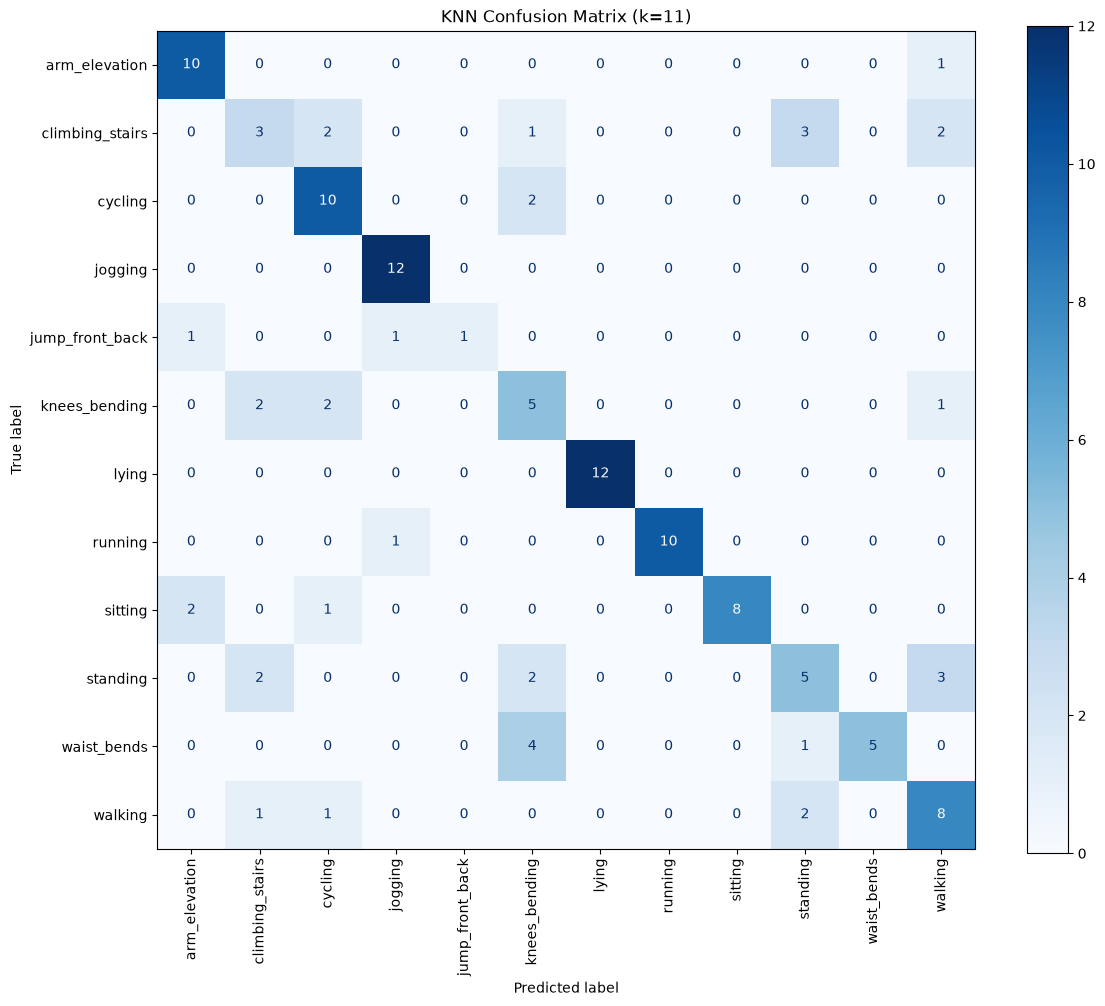

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred, labels=best_knn.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_knn.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", values_format="d")
plt.title("KNN Confusion Matrix (k=11)")
plt.tight_layout()
plt.show()

In [13]:
knn_result = {
    "Feature_Set": "Statistical_138",
    "Model": "KNN",
    "Best_k": grid.best_params_["knn__n_neighbors"],
    "CV_Macro_F1": grid.best_score_,
    "Validation_Accuracy": accuracy_score(y_val, y_val_pred),
    "Validation_Macro_F1": f1_score(y_val, y_val_pred, average="macro"),
    "Validation_Weighted_F1": f1_score(y_val, y_val_pred, average="weighted")
}

results = pd.DataFrame([knn_result])

results.to_csv("../../experiments/knn_results.csv", index=False)

results

,Feature_Set,Model,Best_k,CV_Macro_F1,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1
0,Statistical_138,KNN,11,0.647073,0.700787,0.68264,0.698346


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.decomposition import PCA

knn_pca60_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=60)),
    ("knn", KNeighborsClassifier())
])
cv_pca60 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_pca60 = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}

grid_pca60_corrected = GridSearchCV(
    estimator=knn_pca60_pipeline,
    param_grid=param_grid_pca60,
    cv=cv_pca60,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

grid_pca60_corrected.fit(X_train, y_train)

print("Best Parameters:", grid_pca60_corrected.best_params_)
print("Best CV Macro F1:", grid_pca60_corrected.best_score_)

Best Parameters: {'knn__n_neighbors': 13}
Best CV Macro F1: 0.6064026429080609


In [30]:
best_knn_pca60 = grid_pca60_corrected.best_estimator_

y_val_pred_pca60 = best_knn_pca60.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_pca60))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_pca60, average="macro"))

print("Validation Weighted F1:",
      f1_score(y_val, y_val_pred_pca60, average="weighted"))

Validation Accuracy: 0.5905511811023622
Validation Macro F1: 0.5736034993707628
Validation Weighted F1: 0.5829684972242919


In [31]:
knn_pca72_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=72)),
    ("knn", KNeighborsClassifier())
])

cv_pca72 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_pca72 = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}

grid_pca72_corrected = GridSearchCV(
    estimator=knn_pca72_pipeline,
    param_grid=param_grid_pca72,
    cv=cv_pca72,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

grid_pca72_corrected.fit(X_train, y_train)

print("Best Parameters:", grid_pca72_corrected.best_params_)
print("Best CV Macro F1:", grid_pca72_corrected.best_score_)

Best Parameters: {'knn__n_neighbors': 13}
Best CV Macro F1: 0.5964488037662422


In [32]:
best_knn_pca72 = grid_pca72_corrected.best_estimator_

y_val_pred_pca72 = best_knn_pca72.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_pca72))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_pca72, average="macro"))

print("Validation Weighted F1:",
      f1_score(y_val, y_val_pred_pca72, average="weighted"))

Validation Accuracy: 0.6614173228346457
Validation Macro F1: 0.6496659703767547
Validation Weighted F1: 0.6613187928843325


In [22]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("Features:", X_train.shape[1])
print("Classes:", y_train.nunique())

X_train: (508, 138)
y_train: (508,)
X_val: (127, 138)
y_val: (127,)
Features: 138
Classes: 12


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

knn_lda_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=11)),
    ("knn", KNeighborsClassifier())
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}

In [25]:
grid_lda = GridSearchCV(
    estimator=knn_lda_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

grid_lda.fit(X_train, y_train)

print("Best k:", grid_lda.best_params_)
print("Best CV Macro F1:", grid_lda.best_score_)

Best k: {'knn__n_neighbors': 3}
Best CV Macro F1: 0.924070503799606


In [26]:
best_knn_lda = grid_lda.best_estimator_

y_val_pred_lda = best_knn_lda.predict(X_val)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_lda))

print("Validation Macro F1:",
      f1_score(y_val, y_val_pred_lda, average="macro"))

print("Validation Weighted F1:",
      f1_score(y_val, y_val_pred_lda, average="weighted"))

Validation Accuracy: 0.889763779527559
Validation Macro F1: 0.894327592697158
Validation Weighted F1: 0.8886050557909508


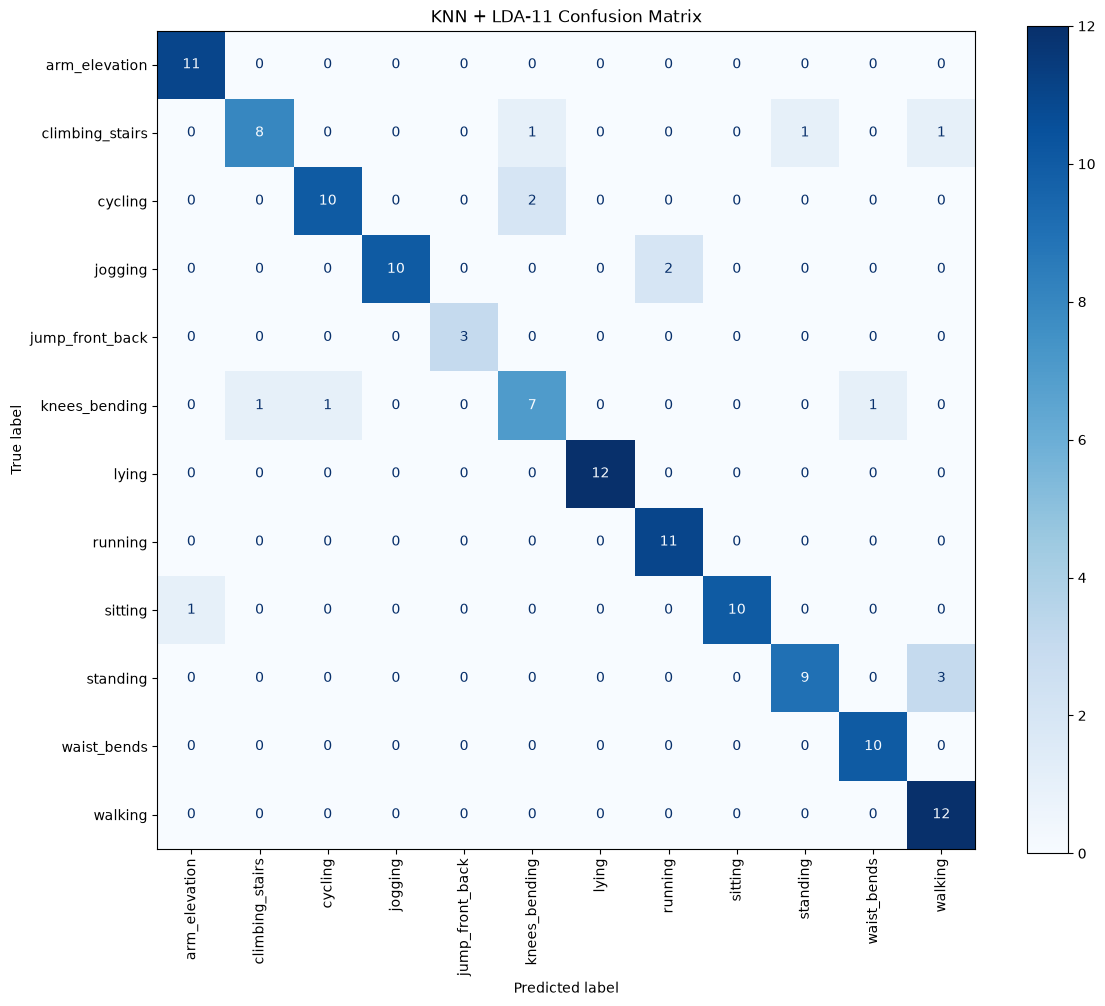

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_lda = confusion_matrix(
    y_val, y_val_pred_lda,
    labels=best_knn_lda.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_lda,
    display_labels=best_knn_lda.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", values_format="d")

plt.title("KNN + LDA-11 Confusion Matrix")
plt.tight_layout()
plt.show()

In [28]:
knn_lda_result = {
    "Feature_Set": "LDA_11",
    "Model": "KNN",
    "Best_k": grid_lda.best_params_["knn__n_neighbors"],
    "CV_Macro_F1": grid_lda.best_score_,
    "Validation_Accuracy": accuracy_score(y_val, y_val_pred_lda),
    "Validation_Macro_F1": f1_score(y_val, y_val_pred_lda, average="macro"),
    "Validation_Weighted_F1": f1_score(y_val, y_val_pred_lda, average="weighted")
}

new_result = pd.DataFrame([knn_lda_result])

results = pd.concat([results, new_result], ignore_index=True)

results.to_csv("../../experiments/knn_results.csv", index=False)

results

,Feature_Set,Model,Best_k,CV_Macro_F1,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1
0,Statistical_138,KNN,11,0.647073,0.700787,0.682640,0.698346
1,LDA_11,KNN,3,0.924071,0.889764,0.894328,0.888605


In [33]:
import pandas as pd

knn_comparison = pd.DataFrame([
    {
        "Feature_Set": "Statistical_138",
        "Model": "KNN",
        "Best_k": 11,
        "CV_Macro_F1": 0.647073,
        "Validation_Accuracy": 0.700787,
        "Validation_Macro_F1": 0.682640,
        "Validation_Weighted_F1": 0.698346
    },
    {
        "Feature_Set": "PCA_60",
        "Model": "KNN",
        "Best_k": 13,
        "CV_Macro_F1": 0.606403,
        "Validation_Accuracy": 0.590551,
        "Validation_Macro_F1": 0.573603,
        "Validation_Weighted_F1": 0.582968
    },
    {
        "Feature_Set": "PCA_72",
        "Model": "KNN",
        "Best_k": 13,
        "CV_Macro_F1": 0.596449,
        "Validation_Accuracy": 0.661417,
        "Validation_Macro_F1": 0.649666,
        "Validation_Weighted_F1": 0.661319
    },
    {
        "Feature_Set": "LDA_11",
        "Model": "KNN",
        "Best_k": 3,
        "CV_Macro_F1": 0.924071,
        "Validation_Accuracy": 0.889764,
        "Validation_Macro_F1": 0.894328,
        "Validation_Weighted_F1": 0.888605
    }
])

knn_comparison

,Feature_Set,Model,Best_k,CV_Macro_F1,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1
0,Statistical_138,KNN,11,0.647073,0.700787,0.682640,0.698346
1,PCA_60,KNN,13,0.606403,0.590551,0.573603,0.582968
2,PCA_72,KNN,13,0.596449,0.661417,0.649666,0.661319
3,LDA_11,KNN,3,0.924071,0.889764,0.894328,0.888605


In [34]:
raw_train = pd.read_csv("../../data/processed/train_imputed.csv")

X_raw = raw_train.drop(columns=["id", "target"])
y_raw = raw_train["target"]

print("X:", X_raw.shape)
print("y:", y_raw.shape)
print("Missing values:", X_raw.isna().sum().sum())

X: (635, 5750)
y: (635,)
Missing values: 0


In [35]:
X_raw_train, X_raw_val, y_raw_train, y_raw_val = train_test_split(
    X_raw,
    y_raw,
    test_size=0.20,
    random_state=42,
    stratify=y_raw
)

print("Train:", X_raw_train.shape)
print("Validation:", X_raw_val.shape)

Train: (508, 5750)
Validation: (127, 5750)


In [36]:
knn_raw_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

In [37]:
cv_raw = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_raw = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}

In [38]:
grid_raw = GridSearchCV(
    estimator=knn_raw_pipeline,
    param_grid=param_grid_raw,
    cv=cv_raw,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=True
)

grid_raw.fit(X_raw_train, y_raw_train)

print("Best Parameters:", grid_raw.best_params_)
print("Best CV Macro F1:", grid_raw.best_score_)

Best Parameters: {'knn__n_neighbors': 5}
Best CV Macro F1: 0.32652290041739435


In [39]:
best_knn_raw = grid_raw.best_estimator_

y_raw_val_pred = best_knn_raw.predict(X_raw_val)

print("Validation Accuracy:",
      accuracy_score(y_raw_val, y_raw_val_pred))

print("Validation Macro F1:",
      f1_score(y_raw_val, y_raw_val_pred, average="macro"))

print("Validation Weighted F1:",
      f1_score(y_raw_val, y_raw_val_pred, average="weighted"))

Validation Accuracy: 0.4015748031496063
Validation Macro F1: 0.3445366232208337
Validation Weighted F1: 0.3730048760467327


In [40]:
import pandas as pd

knn_comparison = pd.DataFrame([
    {
        "Feature_Set": "Raw_Imputed_5750",
        "Model": "KNN",
        "Best_k": 5,
        "CV_Macro_F1": 0.326523,
        "Validation_Accuracy": 0.401575,
        "Validation_Macro_F1": 0.344537,
        "Validation_Weighted_F1": 0.373005
    },
    {
        "Feature_Set": "Statistical_138",
        "Model": "KNN",
        "Best_k": 11,
        "CV_Macro_F1": 0.647073,
        "Validation_Accuracy": 0.700787,
        "Validation_Macro_F1": 0.682640,
        "Validation_Weighted_F1": 0.698346
    },
    {
        "Feature_Set": "PCA_60",
        "Model": "KNN",
        "Best_k": 13,
        "CV_Macro_F1": 0.606403,
        "Validation_Accuracy": 0.590551,
        "Validation_Macro_F1": 0.573603,
        "Validation_Weighted_F1": 0.582968
    },
    {
        "Feature_Set": "PCA_72",
        "Model": "KNN",
        "Best_k": 13,
        "CV_Macro_F1": 0.596449,
        "Validation_Accuracy": 0.661417,
        "Validation_Macro_F1": 0.649666,
        "Validation_Weighted_F1": 0.661319
    },
    {
        "Feature_Set": "LDA_11",
        "Model": "KNN",
        "Best_k": 3,
        "CV_Macro_F1": 0.924071,
        "Validation_Accuracy": 0.889764,
        "Validation_Macro_F1": 0.894328,
        "Validation_Weighted_F1": 0.888605
    }
])

knn_comparison

,Feature_Set,Model,Best_k,CV_Macro_F1,Validation_Accuracy,Validation_Macro_F1,Validation_Weighted_F1
0,Raw_Imputed_5750,KNN,5,0.326523,0.401575,0.344537,0.373005
1,Statistical_138,KNN,11,0.647073,0.700787,0.682640,0.698346
2,PCA_60,KNN,13,0.606403,0.590551,0.573603,0.582968
3,PCA_72,KNN,13,0.596449,0.661417,0.649666,0.661319
4,LDA_11,KNN,3,0.924071,0.889764,0.894328,0.888605


In [44]:
test = pd.read_csv("../../data/processed/test_features_138.csv")

X_test = test.drop(columns=["id"])

print("Test shape:", X_test.shape)

y_test_pred_lda = best_knn_lda.predict(X_test)

print("Predictions shape:", y_test_pred_lda.shape)
print("First 10 predictions:", y_test_pred_lda[:10])

Test shape: (403, 138)
Predictions shape: (403,)
First 10 predictions: ['running' 'running' 'running' 'running' 'running' 'lying' 'running'
 'running' 'running' 'running']


In [45]:
submission = pd.DataFrame({
    "id": test["id"],
    "target": y_test_pred_lda
})

print(submission.head())
print("Shape:", submission.shape)
print("Missing values:", submission.isna().sum().sum())

         id   target
0  TE000001  running
1  TE000002  running
2  TE000003  running
3  TE000004  running
4  TE000005  running
Shape: (403, 2)
Missing values: 0


In [47]:
submission.to_csv("../../submissions.csv", index=False)

In [48]:
submission.to_csv("../../submissions/submissions.csv", index=False)